# Phase 1: Credit Card Fraud Detection Baseline

Complete Colab notebook using GitHub for code and Google Drive for permanent data and outputs.

The notebook validates the ULB dataset, performs chronological 60/20/20 splitting, trains Dummy and balanced Logistic Regression baselines, selects the threshold on validation data, evaluates once on test data, and saves reproducible artifacts.

> Research POC only. Do not use it for real transaction decisions.


## Permanent storage

- GitHub: code, notebook, configuration, tests.
- Google Drive: `creditcard.csv`, models, metrics, predictions, figures, reports.
- Colab `/content`: temporary execution environment.


In [30]:
# 1. Mount Drive, clone/update GitHub, and install the project
from google.colab import drive
drive.mount('/content/drive')

from pathlib import Path
from datetime import datetime, timezone
import os, sys, subprocess, shutil, json, hashlib, time, random, platform

REPOSITORY_URL = 'https://github.com/deepak-malviyaa/enterprise-adaptive-learning-lab.git'
PROJECT_ROOT = Path('/content/enterprise-adaptive-learning-lab')
DRIVE_ROOT = Path('/content/drive/MyDrive/enterprise-adaptive-learning-lab-data')
DRIVE_DATASET = DRIVE_ROOT / 'raw' / 'creditcard.csv'
DRIVE_OUTPUTS = DRIVE_ROOT / 'outputs'
PROJECT_DATASET = PROJECT_ROOT / 'data' / 'raw' / 'creditcard.csv'

if (PROJECT_ROOT / '.git').exists():
    result = subprocess.run(['git','-C',str(PROJECT_ROOT),'pull','--ff-only'], text=True, capture_output=True)
elif PROJECT_ROOT.exists():
    shutil.rmtree(PROJECT_ROOT)
    result = subprocess.run(['git','clone',REPOSITORY_URL,str(PROJECT_ROOT)], text=True, capture_output=True)
else:
    result = subprocess.run(['git','clone',REPOSITORY_URL,str(PROJECT_ROOT)], text=True, capture_output=True)
print(result.stdout)
print(result.stderr)
if result.returncode != 0:
    raise RuntimeError('Git operation failed. Check repository access.')

required=['README.md','pyproject.toml','configs','data','notebooks','src','tests']
missing=[name for name in required if not (PROJECT_ROOT/name).exists()]
if missing:
    raise FileNotFoundError(f'Incomplete repository clone: {missing}')

pyproject=PROJECT_ROOT/'pyproject.toml'
text=pyproject.read_text(encoding='utf-8').replace('>=3.10,<3.13','>=3.10,<3.14')
pyproject.write_text(text,encoding='utf-8')
os.chdir(PROJECT_ROOT)
install=subprocess.run([sys.executable,'-m','pip','install','-q','-e','.'],text=True,capture_output=True)
print(install.stderr)
if install.returncode != 0:
    raise RuntimeError('Project installation failed.')
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0,str(PROJECT_ROOT))
import src
print('PROJECT READY:',PROJECT_ROOT)


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Updating 0624a87..b886bdc
Fast-forward
 notebooks/10_bfsi_fraud.ipynb | 645 +++++++++++++++++++++++++++++++++++++++++-
 1 file changed, 642 insertions(+), 3 deletions(-)

From https://github.com/deepak-malviyaa/enterprise-adaptive-learning-lab
   0624a87..b886bdc  main       -> origin/main


PROJECT READY: /content/enterprise-adaptive-learning-lab


In [31]:
# 2. Imports and reproducibility
from datetime import datetime, timezone
import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
import yaml
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    average_precision_score, roc_auc_score, precision_score, recall_score,
    f1_score, brier_score_loss, confusion_matrix, classification_report,
    precision_recall_curve
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

SEED = 42
os.environ['PYTHONHASHSEED'] = str(SEED)
random.seed(SEED)
np.random.seed(SEED)
print('Seed:', SEED)


Seed: 42


In [32]:
# 3. Use permanent Drive dataset; upload once if it is missing
DRIVE_DATASET.parent.mkdir(parents=True,exist_ok=True)
if not DRIVE_DATASET.exists():
    from google.colab import files
    uploaded=files.upload()
    if not uploaded:
        raise RuntimeError('No dataset uploaded.')
    name=next(iter(uploaded))
    if name.lower() == 'creditcard.csv':
        DRIVE_DATASET.write_bytes(uploaded[name])
    elif name.lower().endswith('.zip'):
        import zipfile
        temp=Path('/content/fraud_dataset_extracted')
        if temp.exists(): shutil.rmtree(temp)
        temp.mkdir(parents=True)
        with zipfile.ZipFile(Path('/content')/name,'r') as archive:
            archive.extractall(temp)
        candidates=list(temp.rglob('creditcard.csv'))
        if not candidates: raise FileNotFoundError('creditcard.csv not found inside ZIP.')
        shutil.copy2(candidates[0],DRIVE_DATASET)
    else:
        raise ValueError('Upload creditcard.csv or a ZIP containing it.')

PROJECT_DATASET.parent.mkdir(parents=True,exist_ok=True)
if PROJECT_DATASET.exists() or PROJECT_DATASET.is_symlink(): PROJECT_DATASET.unlink()
PROJECT_DATASET.symlink_to(DRIVE_DATASET)
DATA_PATH=PROJECT_DATASET
print('PERMANENT DATASET READY:',DRIVE_DATASET)
print('Size MB:',round(DRIVE_DATASET.stat().st_size/1024**2,2))


PERMANENT DATASET READY: /content/drive/MyDrive/enterprise-adaptive-learning-lab-data/raw/creditcard.csv
Size MB: 143.84


In [33]:
# 4. Create a permanent timestamped run folder
for name in ['runs','models','metrics','predictions','figures','reports']:
    (DRIVE_OUTPUTS/name).mkdir(parents=True,exist_ok=True)
RUN_ID=datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%SZ')+'_phase1_fraud_logistic'
RUN_DIR=DRIVE_OUTPUTS/'runs'/RUN_ID
RUN_DIR.mkdir(parents=True,exist_ok=False)
FIGURE_DIR=RUN_DIR/'figures'
FIGURE_DIR.mkdir()
print('PERMANENT RUN FOLDER:',RUN_DIR)


PERMANENT RUN FOLDER: /content/drive/MyDrive/enterprise-adaptive-learning-lab-data/outputs/runs/20261105T083307Z_phase1_fraud_logistic


In [34]:
# 5. Dataset identity and checksum

def sha256_file(path, block_size=1024 * 1024):
    digest = hashlib.sha256()
    with Path(path).open('rb') as stream:
        for block in iter(lambda: stream.read(block_size), b''):
            digest.update(block)
    return digest.hexdigest()

DATASET_SHA256 = sha256_file(DATA_PATH)
df = pd.read_csv(DATA_PATH)
print('Rows:', f'{len(df):,}')
print('Columns:', len(df.columns))
print('SHA-256:', DATASET_SHA256)
display(df.head())


Rows: 284,807
Columns: 31
SHA-256: 76274b691b16a6c49d3f159c883398e03ccd6d1ee12d9d8ee38f4b4b98551a89


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


## Dataset validation

Loading a CSV is not enough. The notebook now checks that the file has the expected ULB schema and valid target values before any model is trained.


In [35]:
# 6. Validate the ULB dataset contract
EXPECTED_COLUMNS=['Time']+[f'V{i}' for i in range(1,29)]+['Amount','Class']
missing=sorted(set(EXPECTED_COLUMNS)-set(df.columns))
unexpected=sorted(set(df.columns)-set(EXPECTED_COLUMNS))
errors=[]
if df.empty: errors.append('Dataset is empty.')
if missing: errors.append(f'Missing columns: {missing}')
if df.columns.duplicated().any(): errors.append('Duplicate column names exist.')
if 'Class' in df and df['Class'].isna().any(): errors.append('Class contains missing values.')
if 'Class' in df and set(df['Class'].dropna().unique())!={0,1}: errors.append('Class must contain exactly 0 and 1.')
for col in EXPECTED_COLUMNS:
    if col in df and not pd.api.types.is_numeric_dtype(df[col]): errors.append(f'{col} must be numeric.')
if 'Amount' in df and (df['Amount']<0).any(): errors.append('Amount contains negative values.')
if np.isinf(df.select_dtypes(include='number').to_numpy()).any(): errors.append('Numeric data contains infinity.')
if errors:
    raise ValueError('Dataset validation failed: ' + '; '.join(errors))
print('DATASET VALIDATION PASSED')
print('Unexpected columns:',unexpected)


DATASET VALIDATION PASSED
Unexpected columns: []


In [36]:
# 7. Data-quality and class-imbalance summary
missing_summary = pd.DataFrame({
    'missing_count': df.isna().sum(),
    'missing_percent': df.isna().mean() * 100
}).sort_values('missing_count', ascending=False)

duplicate_rows = int(df.duplicated().sum())
class_summary = df['Class'].value_counts().sort_index().rename(index={0:'Legitimate',1:'Fraud'}).to_frame('count')
class_summary['percent'] = class_summary['count'] / len(df) * 100
print('Duplicate rows (reported, not automatically removed):', duplicate_rows)
display(class_summary)
display(missing_summary.head(10))


Duplicate rows (reported, not automatically removed): 1081


,count,percent
Class,,
Legitimate,284315,99.827251
Fraud,492,0.172749


,missing_count,missing_percent
Time,0,0.0
V1,0,0.0
V2,0,0.0
V3,0,0.0
V4,0,0.0
V5,0,0.0
V6,0,0.0
V7,0,0.0
V8,0,0.0
V9,0,0.0


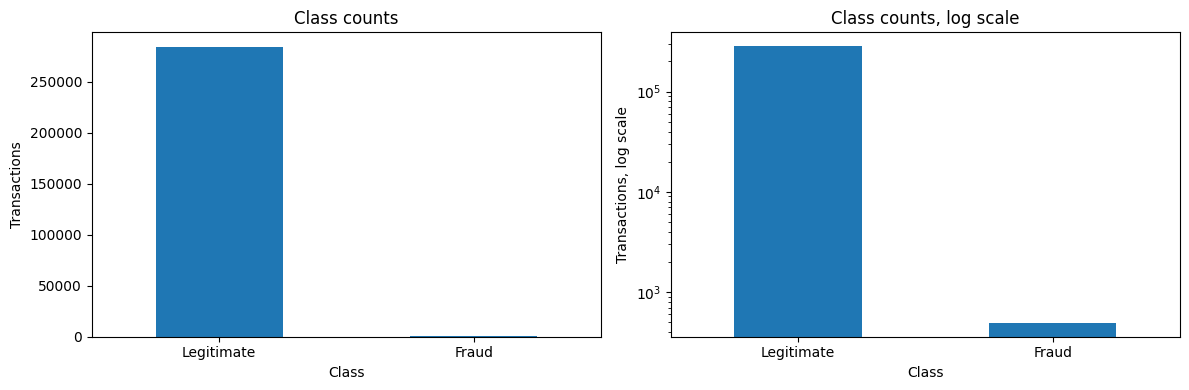

In [37]:
# 8. Class distribution chart
fig,axes=plt.subplots(1,2,figsize=(12,4))
class_summary['count'].plot(kind='bar',ax=axes[0],title='Class counts')
axes[0].set_ylabel('Transactions'); axes[0].tick_params(axis='x',rotation=0)
class_summary['count'].plot(kind='bar',logy=True,ax=axes[1],title='Class counts, log scale')
axes[1].set_ylabel('Transactions, log scale'); axes[1].tick_params(axis='x',rotation=0)
plt.tight_layout(); plt.savefig(FIGURE_DIR/'class_distribution.png',dpi=150,bbox_inches='tight'); plt.show()


## Chronological splitting

The model learns from earlier transactions and is evaluated on later transactions using the available relative `Time` field:

- Earliest 60%: training
- Next 20%: validation
- Latest 20%: final testing

The test partition remains untouched until the model and threshold are finalized.


In [38]:
# 9. Chronological train/validation/test split
df_sorted = df.sort_values('Time', kind='mergesort').reset_index(drop=True)
df_sorted['row_id'] = np.arange(len(df_sorted))
train_end = int(len(df_sorted) * 0.60)
val_end = int(len(df_sorted) * 0.80)
train_df = df_sorted.iloc[:train_end].copy()
val_df = df_sorted.iloc[train_end:val_end].copy()
test_df = df_sorted.iloc[val_end:].copy()

assert train_df['Time'].max() <= val_df['Time'].min()
assert val_df['Time'].max() <= test_df['Time'].min()
assert set(train_df.row_id).isdisjoint(val_df.row_id)
assert set(train_df.row_id).isdisjoint(test_df.row_id)
assert set(val_df.row_id).isdisjoint(test_df.row_id)
for name, part in [('train',train_df),('validation',val_df),('test',test_df)]:
    if part['Class'].nunique() != 2:
        raise ValueError(f'{name} partition does not contain both classes.')

partition_summary = pd.DataFrame([
    {'partition': name, 'rows': len(part), 'frauds': int(part.Class.sum()),
     'fraud_rate': float(part.Class.mean()), 'min_time': float(part.Time.min()),
     'max_time': float(part.Time.max())}
    for name, part in [('train',train_df),('validation',val_df),('test',test_df)]
])
display(partition_summary)


,partition,rows,frauds,fraud_rate,min_time,max_time
0,train,170884,360,0.002107,0.0,120396.0
1,validation,56961,57,0.001001,120396.0,145247.0
2,test,56962,75,0.001317,145248.0,172792.0


In [39]:
# 10. Features and targets
TARGET = 'Class'
DROP_COLUMNS = ['Class', 'row_id']
X_train, y_train = train_df.drop(columns=DROP_COLUMNS), train_df[TARGET]
X_val, y_val = val_df.drop(columns=DROP_COLUMNS), val_df[TARGET]
X_test, y_test = test_df.drop(columns=DROP_COLUMNS), test_df[TARGET]
print(X_train.shape, X_val.shape, X_test.shape)


(170884, 30) (56961, 30) (56962, 30)


## Baselines

The Dummy model establishes the minimum reference. Logistic Regression is the first genuine model. The preprocessing pipeline is fitted only on training data.


In [40]:
# 11. Dummy baseline
dummy = DummyClassifier(strategy='prior', random_state=SEED)
dummy.fit(X_train, y_train)
dummy_val_prob = dummy.predict_proba(X_val)[:, 1]

def ranking_metrics(y_true, prob):
    return {
        'pr_auc': float(average_precision_score(y_true, prob)),
        'roc_auc': float(roc_auc_score(y_true, prob)),
        'brier_score': float(brier_score_loss(y_true, prob))
    }

dummy_val_metrics = ranking_metrics(y_val, dummy_val_prob)
print(dummy_val_metrics)


{'pr_auc': 0.0010006846789908884, 'roc_auc': 0.5, 'brier_score': 0.001000906561931328}


In [41]:
# 12. Balanced Logistic Regression pipeline
scaled_features = ['Time', 'Amount']
pca_features = [f'V{i}' for i in range(1, 29)]
preprocessor = ColumnTransformer([
    ('scaled', Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler())
    ]), scaled_features),
    ('pca', Pipeline([
        ('imputer', SimpleImputer(strategy='median'))
    ]), pca_features)
])
logistic = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(
        class_weight='balanced', max_iter=2000, random_state=SEED
    ))
])
start = time.perf_counter()
logistic.fit(X_train, y_train)
training_seconds = time.perf_counter() - start
val_prob = logistic.predict_proba(X_val)[:, 1]
logistic_val_metrics = ranking_metrics(y_val, val_prob)
print('Training seconds:', round(training_seconds, 3))
print(logistic_val_metrics)


Training seconds: 2.739
{'pr_auc': 0.7715517684407991, 'roc_auc': 0.9709877639409926, 'brier_score': 0.028274908615917718}


,pr_auc,roc_auc,brier_score
model,,,
dummy_prior,0.001001,0.500000,0.001001
logistic_regression,0.771552,0.970988,0.028275


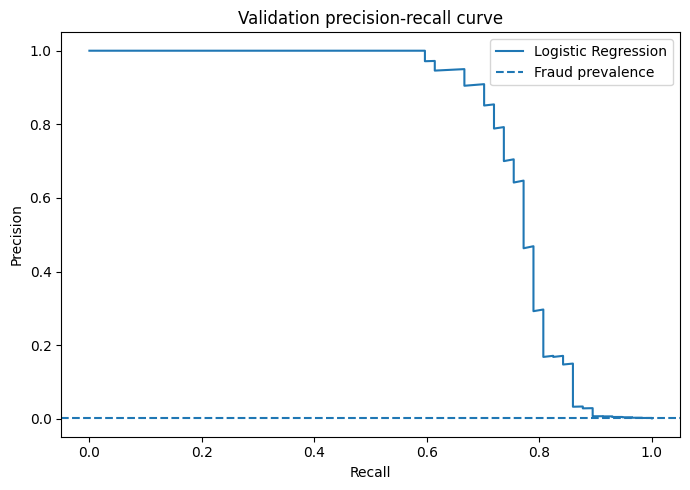

In [42]:
# 13. Compare validation ranking performance
validation_comparison = pd.DataFrame([
    {'model':'dummy_prior', **dummy_val_metrics},
    {'model':'logistic_regression', **logistic_val_metrics}
]).set_index('model')
display(validation_comparison)

precision_curve, recall_curve, _ = precision_recall_curve(y_val, val_prob)
plt.figure(figsize=(7,5))
plt.plot(recall_curve, precision_curve, label='Logistic Regression')
plt.axhline(y_val.mean(), linestyle='--', label='Fraud prevalence')
plt.xlabel('Recall'); plt.ylabel('Precision'); plt.title('Validation precision-recall curve')
plt.legend(); plt.tight_layout()
plt.savefig(FIGURE_DIR / 'validation_precision_recall_curve.png', dpi=150, bbox_inches='tight')
plt.show()


## Threshold selection

The model returns probabilities. The validation partition selects the threshold. The test partition is not used here.


In [43]:
# 14. Evaluate thresholds only on validation data
thresholds = np.round(np.arange(0.01, 1.00, 0.01), 2)
rows=[]
for threshold in thresholds:
    pred=(val_prob >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_val, pred, labels=[0,1]).ravel()
    rows.append({
        'threshold':float(threshold), 'precision':float(precision_score(y_val,pred,zero_division=0)),
        'recall':float(recall_score(y_val,pred,zero_division=0)),
        'f1':float(f1_score(y_val,pred,zero_division=0)), 'alerts':int(pred.sum()),
        'tn':int(tn),'fp':int(fp),'fn':int(fn),'tp':int(tp)
    })
threshold_results=pd.DataFrame(rows)
best_f1=threshold_results.f1.max()
best_candidates=threshold_results[threshold_results.f1 == best_f1]
selected=best_candidates.sort_values(['recall','threshold'], ascending=[False,True]).iloc[0]
SELECTED_THRESHOLD=float(selected.threshold)
print('Selected validation threshold:', SELECTED_THRESHOLD)
display(threshold_results.sort_values('f1', ascending=False).head(10))


Selected validation threshold: 0.99


,threshold,precision,recall,f1,alerts,tn,fp,fn,tp
98,0.99,0.473118,0.771930,0.586667,93,56855,49,13,44
97,0.98,0.398230,0.789474,0.529412,113,56836,68,12,45
96,0.97,0.328467,0.789474,0.463918,137,56812,92,12,45
95,0.96,0.287500,0.807018,0.423963,160,56790,114,11,46
94,0.95,0.250000,0.807018,0.381743,184,56766,138,11,46
93,0.94,0.220096,0.807018,0.345865,209,56741,163,11,46
92,0.93,0.198276,0.807018,0.318339,232,56718,186,11,46
91,0.92,0.177606,0.807018,0.291139,259,56691,213,11,46
90,0.91,0.169065,0.824561,0.280597,278,56673,231,10,47
89,0.90,0.163265,0.842105,0.273504,294,56658,246,9,48


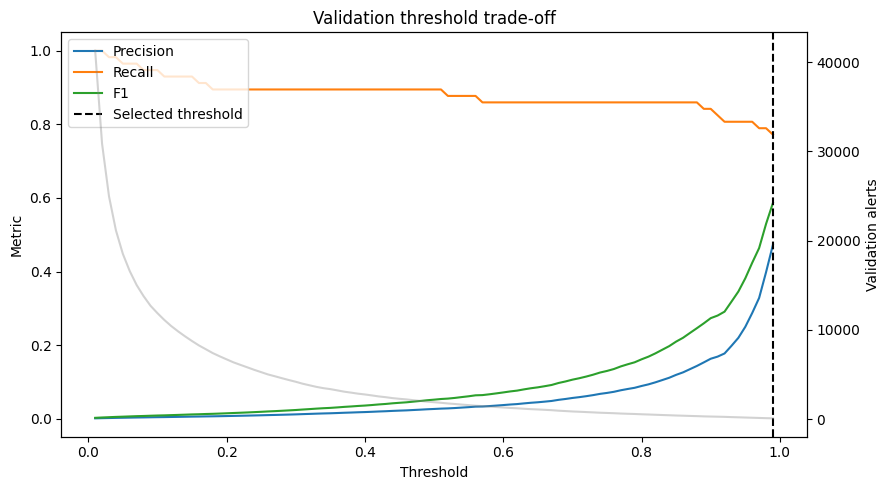

In [44]:
# 15. Threshold trade-off chart
fig, ax1 = plt.subplots(figsize=(9,5))
ax1.plot(threshold_results.threshold, threshold_results.precision, label='Precision')
ax1.plot(threshold_results.threshold, threshold_results.recall, label='Recall')
ax1.plot(threshold_results.threshold, threshold_results.f1, label='F1')
ax1.axvline(SELECTED_THRESHOLD, color='black', linestyle='--', label='Selected threshold')
ax1.set_xlabel('Threshold'); ax1.set_ylabel('Metric'); ax1.legend(loc='upper left')
ax2=ax1.twinx(); ax2.plot(threshold_results.threshold, threshold_results.alerts, color='gray', alpha=.35, label='Alerts')
ax2.set_ylabel('Validation alerts')
plt.title('Validation threshold trade-off'); plt.tight_layout()
plt.savefig(FIGURE_DIR / 'threshold_tradeoff.png', dpi=150, bbox_inches='tight')
plt.show()


## Final test evaluation

The model and threshold are now fixed. This is the first and only Phase 1 evaluation on the test partition.


In [45]:
# 16. Final test evaluation
test_prob=logistic.predict_proba(X_test)[:,1]
test_pred=(test_prob>=SELECTED_THRESHOLD).astype(int)
tn,fp,fn,tp=confusion_matrix(y_test,test_pred,labels=[0,1]).ravel()
test_metrics={
    **ranking_metrics(y_test,test_prob),'threshold':SELECTED_THRESHOLD,
    'precision':float(precision_score(y_test,test_pred,zero_division=0)),
    'recall':float(recall_score(y_test,test_pred,zero_division=0)),
    'f1':float(f1_score(y_test,test_pred,zero_division=0)),
    'alerts':int(test_pred.sum()),'true_negatives':int(tn),'false_positives':int(fp),
    'false_negatives':int(fn),'true_positives':int(tp),'training_seconds':float(training_seconds)
}
print(json.dumps(test_metrics,indent=2))
print('Plain language:')
print(f'- Detected frauds: {tp}')
print(f'- Missed frauds: {fn}')
print(f'- Legitimate transactions incorrectly flagged: {fp}')
print('Classification report:')
print(classification_report(y_test,test_pred,digits=4,zero_division=0))


{
  "pr_auc": 0.7431313911313588,
  "roc_auc": 0.9819577993800576,
  "brier_score": 0.02284625696065514,
  "threshold": 0.99,
  "precision": 0.5175438596491229,
  "recall": 0.7866666666666666,
  "f1": 0.6243386243386243,
  "alerts": 114,
  "true_negatives": 56832,
  "false_positives": 55,
  "false_negatives": 16,
  "true_positives": 59,
  "training_seconds": 2.739311541000461
}
Plain language:
- Detected frauds: 59
- Missed frauds: 16
- Legitimate transactions incorrectly flagged: 55
Classification report:
              precision    recall  f1-score   support

           0     0.9997    0.9990    0.9994     56887
           1     0.5175    0.7867    0.6243        75

    accuracy                         0.9988     56962
   macro avg     0.7586    0.8928    0.8119     56962
weighted avg     0.9991    0.9988    0.9989     56962



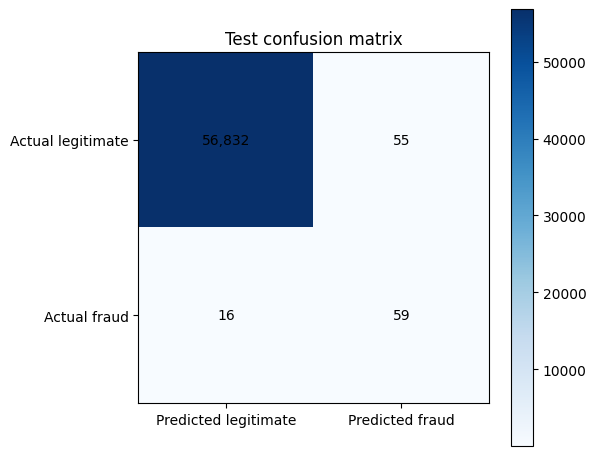

In [46]:
# 17. Confusion matrix chart
cm=np.array([[tn,fp],[fn,tp]])
fig, ax=plt.subplots(figsize=(6,5))
im=ax.imshow(cm, cmap='Blues')
for i in range(2):
    for j in range(2): ax.text(j,i,f'{cm[i,j]:,}',ha='center',va='center')
ax.set_xticks([0,1], labels=['Predicted legitimate','Predicted fraud'])
ax.set_yticks([0,1], labels=['Actual legitimate','Actual fraud'])
ax.set_title('Test confusion matrix'); plt.colorbar(im, ax=ax); plt.tight_layout()
plt.savefig(FIGURE_DIR / 'test_confusion_matrix.png', dpi=150, bbox_inches='tight')
plt.show()


In [47]:
# 18. Review-capacity analysis: Precision@K and Recall@K
def metrics_at_k(y_true, probabilities, k):
    ranked=pd.DataFrame({'actual':np.asarray(y_true), 'probability':np.asarray(probabilities)})             .sort_values('probability', ascending=False)
    selected=ranked.head(min(k,len(ranked)))
    found=int(selected.actual.sum()); total=int(ranked.actual.sum())
    return {'k':int(k), 'frauds_found':found,
            'precision_at_k':float(found/len(selected)),
            'recall_at_k':float(found/total if total else 0.0)}
review_capacity=pd.DataFrame([metrics_at_k(y_test,test_prob,k) for k in [50,100,250,500]])
display(review_capacity)


,k,frauds_found,precision_at_k,recall_at_k
0,50,49,0.980,0.653333
1,100,59,0.590,0.786667
2,250,64,0.256,0.853333
3,500,65,0.130,0.866667


## Persist reproducible artifacts

Colab storage is temporary. The notebook saves a complete run folder and offers a ZIP download. You can also copy the ZIP to Google Drive.


In [48]:
# 19. Save reproducible artifacts permanently to Drive
config={
 'phase':'phase_1_fraud_baseline','seed':SEED,'dataset_path':str(DRIVE_DATASET),
 'dataset_sha256':DATASET_SHA256,'split':{'strategy':'chronological','train':0.60,'validation':0.20,'test':0.20},
 'model':'logistic_regression','class_weight':'balanced','max_iter':2000,
 'threshold_selection':'maximum validation F1','selected_threshold':SELECTED_THRESHOLD,
 'review_capacity':[50,100,250,500]
}
metadata={
 'rows':len(df),'columns':len(df.columns),'frauds':int(df.Class.sum()),
 'fraud_rate':float(df.Class.mean()),'duplicate_rows':duplicate_rows,
 'missing_values':{k:int(v) for k,v in df.isna().sum().items()},
 'python':sys.version,'pandas':pd.__version__,'numpy':np.__version__,'sklearn':sklearn.__version__,
 'platform':platform.platform()
}
predictions=pd.DataFrame({
 'row_id':test_df.row_id.to_numpy(),'Time':test_df.Time.to_numpy(),'Amount':test_df.Amount.to_numpy(),
 'actual_class':y_test.to_numpy(),'fraud_probability':test_prob,'predicted_class':test_pred,
 'selected_threshold':SELECTED_THRESHOLD
})
joblib.dump(logistic,RUN_DIR/'logistic_regression_pipeline.joblib')
(RUN_DIR/'config.yaml').write_text(yaml.safe_dump(config,sort_keys=False),encoding='utf-8')
(RUN_DIR/'dataset_and_environment.json').write_text(json.dumps(metadata,indent=2),encoding='utf-8')
(RUN_DIR/'validation_metrics.json').write_text(json.dumps({'dummy':dummy_val_metrics,'logistic':logistic_val_metrics},indent=2),encoding='utf-8')
(RUN_DIR/'test_metrics.json').write_text(json.dumps(test_metrics,indent=2),encoding='utf-8')
threshold_results.to_csv(RUN_DIR/'validation_thresholds.csv',index=False)
review_capacity.to_csv(RUN_DIR/'review_capacity.csv',index=False)
predictions.to_csv(RUN_DIR/'test_predictions.csv',index=False)
partition_summary.to_csv(RUN_DIR/'partition_summary.csv',index=False)
report=(
 '# Phase 1 Fraud Detection Report\n\n'
 '## Executive summary\nBalanced Logistic Regression used chronological 60/20/20 partitions. '
 'The threshold was selected on validation data and evaluated once on test data.\n\n'
 f'## Dataset\n- Rows: {len(df):,}\n- Frauds: {int(df.Class.sum()):,}\n'
 f'- Fraud rate: {df.Class.mean():.6%}\n- SHA-256: `{DATASET_SHA256}`\n\n'
 f'## Test results\n- PR-AUC: {test_metrics["pr_auc"]:.6f}\n'
 f'- ROC-AUC: {test_metrics["roc_auc"]:.6f}\n- Precision: {test_metrics["precision"]:.6f}\n'
 f'- Recall: {test_metrics["recall"]:.6f}\n- F1: {test_metrics["f1"]:.6f}\n'
 f'- Threshold: {SELECTED_THRESHOLD:.4f}\n- Detected frauds: {tp}\n- Missed frauds: {fn}\n'
 f'- Legitimate transactions incorrectly flagged: {fp}\n\n'
 '## Limitations\n- Research POC only.\n- V1-V28 are anonymized transformed features.\n'
 '- Time is relative, not a production timestamp.\n- The threshold does not represent validated banking costs.\n\n'
 '## Next phase\nAdd XGBoost using the same split and evaluation protocol.\n'
)
(RUN_DIR/'report.md').write_text(report,encoding='utf-8')
print('ARTIFACTS SAVED:',RUN_DIR)


ARTIFACTS SAVED: /content/drive/MyDrive/enterprise-adaptive-learning-lab-data/outputs/runs/20261105T083307Z_phase1_fraud_logistic


In [49]:
# 20. Create a permanent ZIP of the run
archive_path=Path(shutil.make_archive(str(RUN_DIR),'zip',root_dir=RUN_DIR))
print('Permanent run ZIP:',archive_path)


Permanent run ZIP: /content/drive/MyDrive/enterprise-adaptive-learning-lab-data/outputs/runs/20261105T083307Z_phase1_fraud_logistic.zip


In [50]:
# 21. Automated Phase 1 acceptance checks
checks={
    'dataset_exists':DATA_PATH.exists(),'dataset_schema_valid':set(EXPECTED_COLUMNS).issubset(df.columns),
    'chronological_train_to_validation':train_df.Time.max() <= val_df.Time.min(),
    'chronological_validation_to_test':val_df.Time.max() <= test_df.Time.min(),
    'partitions_disjoint':set(train_df.row_id).isdisjoint(val_df.row_id) and set(train_df.row_id).isdisjoint(test_df.row_id) and set(val_df.row_id).isdisjoint(test_df.row_id),
    'both_classes_all_partitions':all(p.Class.nunique()==2 for p in [train_df,val_df,test_df]),
    'threshold_selected_from_validation':0 < SELECTED_THRESHOLD < 1,
    'model_saved':(RUN_DIR/'logistic_regression_pipeline.joblib').exists(),
    'metrics_saved':(RUN_DIR/'test_metrics.json').exists(),
    'predictions_saved':(RUN_DIR/'test_predictions.csv').exists(),
    'report_saved':(RUN_DIR/'report.md').exists()
}
display(pd.Series(checks,name='passed').to_frame())
failed=[name for name,passed in checks.items() if not passed]
if failed: raise AssertionError(f'Phase 1 checks failed: {failed}')
print('PHASE 1 COMPLETED SUCCESSFULLY')


,passed
dataset_exists,True
dataset_schema_valid,True
chronological_train_to_validation,True
chronological_validation_to_test,True
partitions_disjoint,True
both_classes_all_partitions,True
threshold_selected_from_validation,True
model_saved,True
metrics_saved,True
predictions_saved,True


PHASE 1 COMPLETED SUCCESSFULLY


## Save notebook to GitHub
After success, use **File → Save a copy in GitHub** and save as `notebooks/10_bfsi_fraud.ipynb`.
